# Week 8 — Modeling with systems of differential equations

Companion notebook of the eighth lecture. Two or more quantities that change together form a **system** of differential equations, and the state becomes a point in the **phase plane**. We draw phase portraits with `streamplot`, find rest points and classify them with the **Jacobian**, rebuild the competitive hunter, predator–prey, and Lanchester combat models of Chapter 12, run Euler's method for systems (and watch it fail), solve the SIR epidemic model, and finally rebuild the **2021 MCM Problem A** fungi model of Team 2100454 and check its three-species experiment against their figures.

**How to run**: Anaconda locally (`jupyter lab`), or Colab/Binder from the [course repository](https://github.com/liwt31/MathModel). Run cells in order with `Shift+Enter`.

**Note.** The exercises here and on the slides are **practice for yourself**, and they are **not** the graded assignments. Problem sets are released separately on Blackboard, with due dates.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks
try:                                  # optional style file, ships with the course
    plt.style.use("mm.mplstyle")
except OSError:
    pass
# one size for every figure, so the plots fit the notebook column; legends stay small
plt.rcParams.update({"figure.figsize": (6.4, 4.0), "figure.dpi": 100, "legend.fontsize": 9,
                     "legend.framealpha": 0.9, "axes.titlesize": 11})

def portrait(f, xlim, ylim, starts=(), T=10, ax=None, density=1.0, title=""):
    # phase portrait of x' = f(x, y)[0], y' = f(x, y)[1]: streamlines plus solution curves from `starts`
    ax = ax or plt.gca()
    X, Y = np.meshgrid(np.linspace(*xlim, 40), np.linspace(*ylim, 40))
    U, V = f(X, Y)
    ax.streamplot(X, Y, U, V, color="0.7", density=density, broken_streamlines=False)
    for z0 in starts:
        s = solve_ivp(lambda t, z: f(*z), [0, T], z0, max_step=0.01)
        ax.plot(s.y[0], s.y[1], lw=2); ax.plot(*z0, "ko", ms=4)
    ax.set(xlim=xlim, ylim=ylim, xlabel="x", ylabel="y", title=title)
    return ax

## 1. The phase plane: two linear examples

Example 1 of Section 12.1: $x' = -x + y$, $y' = -x - y$ has the solution $x = e^{-t}\sin t$, $y = e^{-t}\cos t$, and $x^2 + y^2 = e^{-2t}$ shrinks to zero, so the origin is **asymptotically stable**.

check x' = -x + y: True


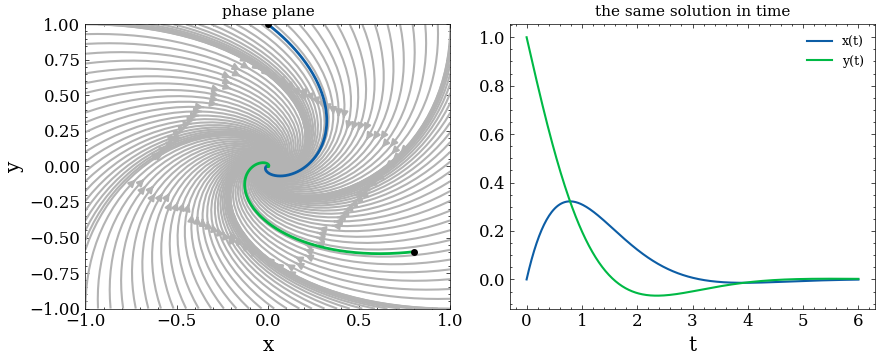

In [2]:
t = np.linspace(0, 6, 400)
x, y = np.exp(-t) * np.sin(t), np.exp(-t) * np.cos(t)
dx = -np.exp(-t) * np.sin(t) + np.exp(-t) * np.cos(t)       # derivative of e^{-t} sin t
print("check x' = -x + y:", np.allclose(dx, -x + y))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
portrait(lambda x, y: (-x + y, -x - y), (-1, 1), (-1, 1), starts=[(0, 1), (0.8, -0.6)], ax=ax[0], title="phase plane")
ax[1].plot(t, x, label="x(t)"); ax[1].plot(t, y, label="y(t)"); ax[1].legend(); ax[1].set(xlabel="t", title="the same solution in time")
plt.tight_layout(); plt.show()

## 2. Competitive hunters: trout and bass

$x' = (a - by)x$, $y' = (m - nx)y$. The rest points are $(0,0)$ and $(m/n, a/b)$, and both are unstable: the interior point is a **saddle**, and the two trajectories that enter it (the separatrices) divide the plane into "trout win" and "bass win". With $a = b = m = n = 1$ the saddle sits at $(1, 1)$.

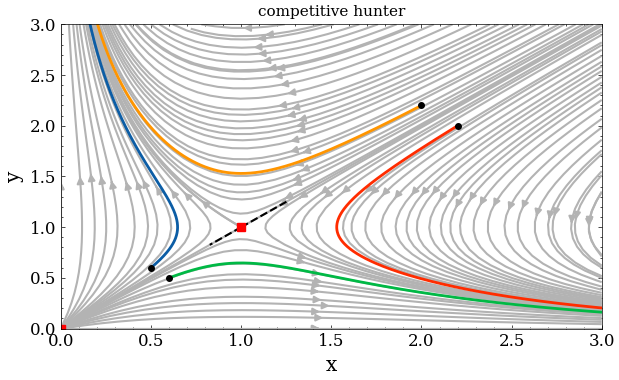

Jacobian eigenvalues at (m/n, a/b): [ 1. -1.]


In [3]:
a = b = m = n = 1.0
f = lambda x, y: ((a - b * y) * x, (m - n * x) * y)
ax = portrait(f, (0, 3), (0, 3), starts=[(0.5, 0.6), (0.6, 0.5), (2, 2.2), (2.2, 2)], T=6, title="competitive hunter")
# the separatrices: integrate backward in time from points just off the saddle along its stable direction
J = np.array([[0, -b * m / n], [-n * a / b, 0]])
w, v = np.linalg.eig(J); vs = v[:, np.argmin(w)]
for sgn in (1, -1):
    s = solve_ivp(lambda t, z: [-c for c in f(*z)], [0, 8], [m / n + 1e-4 * sgn * vs[0], a / b + 1e-4 * sgn * vs[1]],
                  max_step=0.01, events=lambda t, z: min(z[0], z[1], 3.2 - max(z)))
    ax.plot(s.y[0], s.y[1], "k--", lw=1.5)
ax.plot([0, m / n], [0, a / b], "rs"); plt.tight_layout(); plt.show()
print("Jacobian eigenvalues at (m/n, a/b):", w)

### With self-limitation: coexistence becomes possible

Problem 5 of Section 12.5: $B' = B(10 - B - T)$, $T' = T(15 - B - 3T)$. The rest points are $(0,0)$, $(10,0)$, $(0,5)$ and $(7.5, 2.5)$; the Jacobian decides which one attracts.

(0, 0) eigenvalues [10. 15.]
(10, 0) eigenvalues [-10.   5.]
(0, 5) eigenvalues [-15.   5.]
(7.5, 2.5) eigenvalues [ -3.17 -11.83]


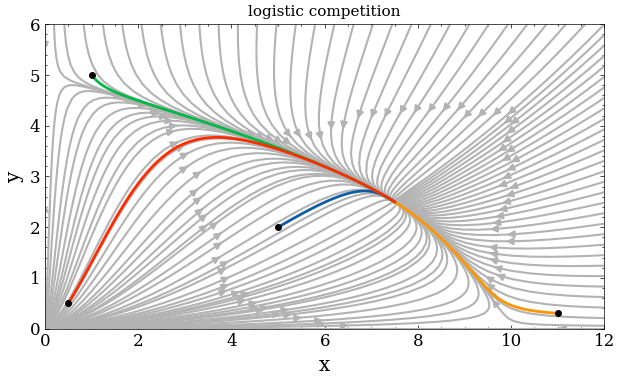

In [4]:
fB = lambda B, T: (B * (10 - B - T), T * (15 - B - 3 * T))
def jac(f, z, h=1e-6):
    z = np.asarray(z, float); J = np.zeros((2, 2))
    for j in range(2):
        e = np.zeros(2); e[j] = h
        J[:, j] = (np.array(f(*(z + e))) - np.array(f(*(z - e)))) / (2 * h)
    return J
for p in [(0, 0), (10, 0), (0, 5), (7.5, 2.5)]:
    print(p, "eigenvalues", np.round(np.linalg.eigvals(jac(fB, p)), 3))
portrait(fB, (0, 12), (0, 6), starts=[(5, 2), (1, 5), (11, 0.3), (0.5, 0.5)], T=5, title="logistic competition")
plt.tight_layout(); plt.show()

## 3. Predator and prey: whales and krill

$x' = (a - by)x$ (krill), $y' = (-m + nx)y$ (whales), with $a = 3$, $b = 1$, $m = 2$, $n = 1$ as in Section 12.5. The orbits close because $y^a x^m e^{-by - nx}$ is constant along them; the time averages over one cycle equal the rest point $(m/n, a/b) = (2, 3)$.

period 2.6735, predator peak lags prey peak by 0.482
averages over one cycle: x = 2.0000, y = 3.0000  (m/n = 2, a/b = 3)
conserved quantity varies by 8.7e-11


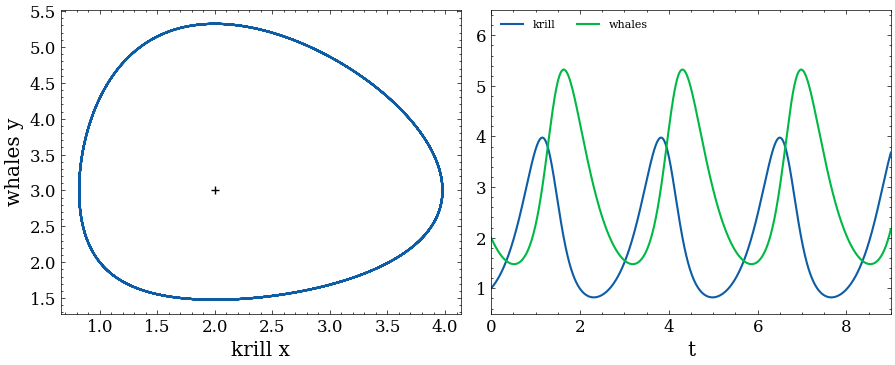

In [5]:
a, b, m, n = 3.0, 1.0, 2.0, 1.0
pp = lambda t, z: [(a - b * z[1]) * z[0], (-m + n * z[0]) * z[1]]
s = solve_ivp(pp, [0, 20], [1, 2], rtol=1e-11, atol=1e-12, dense_output=True)
t = np.linspace(0, 20, 200001); x, y = s.sol(t)
px, _ = find_peaks(x); py, _ = find_peaks(y)
T = np.diff(t[px]).mean()
H = b * y + n * x - a * np.log(y) - m * np.log(x)            # the conserved quantity
one = (t >= t[px[0]]) & (t < t[px[1]])
print(f"period {T:.4f}, predator peak lags prey peak by {np.mean(t[py[:3]] - t[px[:3]]):.3f}")
print(f"averages over one cycle: x = {x[one].mean():.4f}, y = {y[one].mean():.4f}  (m/n = 2, a/b = 3)")
print(f"conserved quantity varies by {H.max() - H.min():.1e}")
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
ax[0].plot(x, y); ax[0].plot(2, 3, "k+"); ax[0].set(xlabel="krill x", ylabel="whales y")
ax[1].plot(t, x, label="krill"); ax[1].plot(t, y, label="whales"); ax[1].set(xlim=(0, 9), ylim=(0.5, 6.5), xlabel="t"); ax[1].legend(loc="upper left", ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

### Harvesting and Volterra's principle

Fishing at intensity $r$ removes $rx$ krill and, through the food chain, $ry$ whales. The averages move to $\bar x = (m + r)/n$ and $\bar y = (a - r)/b$.

In [6]:
def averages(r, z0=(1, 2)):
    f = lambda t, z: [((a - r) - b * z[1]) * z[0], (-(m + r) + n * z[0]) * z[1]]
    s = solve_ivp(f, [0, 40], z0, rtol=1e-10, atol=1e-12, dense_output=True)
    t = np.linspace(0, 40, 400001); x, y = s.sol(t)
    pk, _ = find_peaks(x); sel = (t >= t[pk[0]]) & (t < t[pk[-1]])
    return x[sel].mean(), y[sel].mean()
for r in [0, 0.5, 1.0, 2.0]:
    xb, yb = averages(r)
    print(f"r = {r}: krill average {xb:.3f} (theory {(m + r) / n:.3f}), whale average {yb:.3f} (theory {(a - r) / b:.3f})")

r = 0: krill average 2.000 (theory 2.000), whale average 3.000 (theory 3.000)
r = 0.5: krill average 2.500 (theory 2.500), whale average 2.500 (theory 2.500)


r = 1.0: krill average 3.000 (theory 3.000), whale average 2.000 (theory 2.000)
r = 2.0: krill average 4.000 (theory 4.000), whale average 1.000 (theory 1.000)


## 4. Lanchester's square law

Aimed fire: $x' = -ay$, $y' = -bx$. Along every trajectory $a y^2 - b x^2 = C$ is constant, so $Y$ wins if $(y_0/x_0)^2 > b/a$, with $\sqrt{C/a}$ survivors. Problem 2 of Section 12.4: with $a = b$, 50,000 soldiers meet 40,000 and then 30,000 separately.

In [7]:
def battle(x0, y0, a, b, aimed=True):
    if aimed:
        f = lambda t, z: [-a * z[1], -b * z[0]]
    else:                                             # area fire: losses proportional to both forces
        f = lambda t, z: [-a * z[0] * z[1], -b * z[0] * z[1]]
    end = lambda t, z: min(z[0], z[1]); end.terminal = True
    s = solve_ivp(f, [0, 1e6], [x0, y0], events=end, rtol=1e-10, atol=1e-6)
    return s.t[-1], s.y[0, -1], s.y[1, -1]
t1, x1, y1 = battle(40000, 50000, 1e-3, 1e-3)
t2, x2, y2 = battle(30000, y1, 1e-3, 1e-3)
print(f"Y meets 40,000: Y has {y1:,.0f} left (square law {np.sqrt(50000**2 - 40000**2):,.0f})")
print(f"then meets 30,000: X {abs(x2):,.0f}, Y {abs(y2):,.0f}  (a draw)")
print(f"against the united 70,000 at once: 50,000^2 - 70,000^2 = {50000**2 - 70000**2:,} < 0, so Y would lose")

Y meets 40,000: Y has 30,000 left (square law 30,000)
then meets 30,000: X 0, Y 0  (a draw)
against the united 70,000 at once: 50,000^2 - 70,000^2 = -2,400,000,000 < 0, so Y would lose


## 5. Linear systems and the Jacobian

For $z' = Az$ the eigenvalues of $A$ decide the picture: real and of one sign (node), real of opposite signs (saddle), complex (spiral, or a center when the real part is zero). Trace and determinant classify it without computing the eigenvalues.

In [8]:
def classify(A):
    tr, det = np.trace(A), np.linalg.det(A); disc = tr**2 - 4 * det
    if det < 0: kind = "saddle (unstable)"
    elif abs(tr) < 1e-12: kind = "center (linear: neutral)"
    elif disc >= 0: kind = "stable node" if tr < 0 else "unstable node"
    else: kind = "stable spiral" if tr < 0 else "unstable spiral"
    return tr, det, kind
for name, A in {"Example 1": [[-1, 1], [-1, -1]], "saddle": [[1, 0], [0, -2]],
                "center": [[0, 2], [-3, 0]], "refined competition at (7.5, 2.5)": jac(fB, (7.5, 2.5)),
                "predator-prey at (2, 3)": jac(lambda x, y: ((a - b * y) * x, (-m + n * x) * y), (2, 3))}.items():
    A = np.array(A, float); tr, det, kind = classify(A)
    print(f"{name:38s} trace {tr:7.2f}  det {det:7.2f}  eigenvalues {np.round(np.linalg.eigvals(A), 3)}  -> {kind}")

Example 1                              trace   -2.00  det    2.00  eigenvalues [-1.+1.j -1.-1.j]  -> stable spiral
saddle                                 trace   -1.00  det   -2.00  eigenvalues [ 1. -2.]  -> saddle (unstable)
center                                 trace    0.00  det    6.00  eigenvalues [0.+2.449j 0.-2.449j]  -> center (linear: neutral)
refined competition at (7.5, 2.5)      trace  -15.00  det   37.50  eigenvalues [ -3.17 -11.83]  -> stable node
predator-prey at (2, 3)                trace    0.00  det    6.00  eigenvalues [0.+2.449j 0.-2.449j]  -> center (linear: neutral)


## 6. Euler's method for systems

$x_{k+1} = x_k + f(x_k, y_k)\,\Delta t$, $y_{k+1} = y_k + g(x_k, y_k)\,\Delta t$. Example 1 of Section 12.5 on the whale–krill system from $(1, 2)$ with $\Delta t = 0.1$ gives $(1.1, 1.8)$, $(1.232, 1.638)$, $(1.3998, 1.5122)$. On the closed orbit Euler spirals **outward**. On the logistic competition model the fastest eigenvalue at $(7.5, 2.5)$ is $-11.83$, so Euler needs $\Delta t < 2/11.83 = 0.17$: $\Delta t = 0.2$ oscillates away from the rest point, and $\Delta t = 1$ blows up (Problem 6).

[[1.        2.       ]
 [1.1       1.8      ]
 [1.232     1.638    ]
 [1.3997984 1.5122016]]


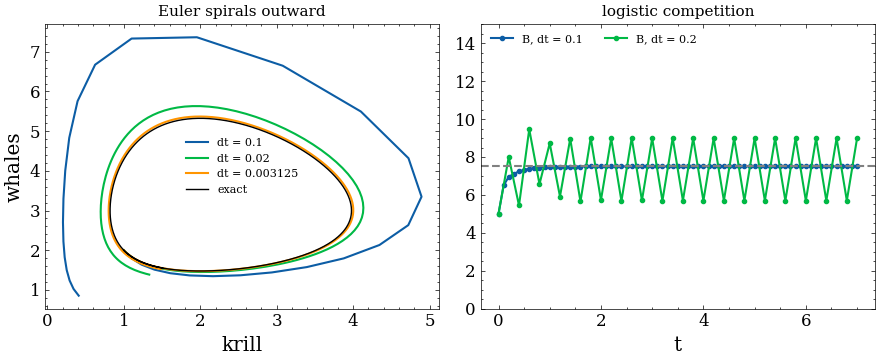

dt = 1: [[5.0, 2.0], [20.0, 10.0], [-380.0, -340.0], [-277780.0, -481440.0]]  (blows up)


In [9]:
def euler(f, z0, dt, T):
    z = np.array(z0, float); out = [z.copy()]
    for _ in range(int(round(T / dt))):
        z = z + dt * np.array(f(0, z)); out.append(z.copy())
    return np.array(out)
print(euler(pp, (1, 2), 0.1, 0.3).round(7))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
for dt in [0.1, 0.02, 0.003125]:
    zz = euler(pp, (1, 2), dt, 3); ax[0].plot(zz[:, 0], zz[:, 1], label=f"dt = {dt}")
ax[0].plot(x[t < 3], y[t < 3], "k", lw=1, label="exact"); ax[0].legend(loc="center", fontsize=8); ax[0].set(xlabel="krill", ylabel="whales", title="Euler spirals outward")
for dt in [0.1, 0.2]:
    zz = euler(lambda t, z: fB(*z), (5, 2), dt, 7); ax[1].plot(np.arange(len(zz)) * dt, zz[:, 0], "o-", ms=3, label=f"B, dt = {dt}")
ax[1].axhline(7.5, c="gray", ls="--"); ax[1].set(xlabel="t", ylim=(0, 15), title="logistic competition"); ax[1].legend(loc="upper left", ncol=2, fontsize=8)
plt.tight_layout(); plt.show()
with np.errstate(over="ignore"):
    print("dt = 1:", euler(lambda t, z: fB(*z), (5, 2), 1.0, 3)[:4].round(1).tolist(), " (blows up)")

## 7. Epidemics: the SIR model

$S' = -\beta SI$, $I' = \beta SI - \gamma I$, $R' = \gamma I$. Infections grow at the start exactly when $R_0 = \beta N/\gamma > 1$. Example 3 of Section 12.5: $\beta = 0.001407$ per person per week, $\gamma = 0.6$ per week, $(S, I, R)(0) = (995, 5, 0)$.

R0 = beta N / gamma = 2.345
peak I = 212.3 at week 6.85, when S = 426.4  (gamma/beta = 426.4)
final: S = 129.1, so 87% of the town is infected
conserved quantity varies by 2.6e-07
vaccinated 0.00: peak I =  212.1
vaccinated 0.30: peak I =   65.8
vaccinated 0.57: peak I =    5.0
vaccinated 0.70: peak I =    5.0


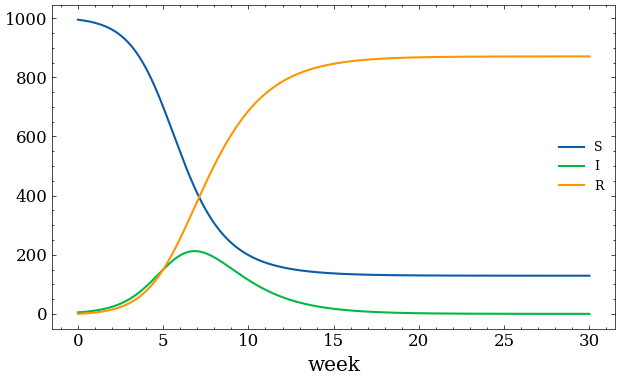

In [10]:
beta, gamma, N = 0.001407, 0.6, 1000
sir = lambda t, z: [-beta * z[0] * z[1], beta * z[0] * z[1] - gamma * z[1], gamma * z[1]]
s = solve_ivp(sir, [0, 30], [995, 5, 0], rtol=1e-10, atol=1e-10, dense_output=True)
tt = np.linspace(0, 30, 300001); S, I, R = s.sol(tt); k = I.argmax()
print(f"R0 = beta N / gamma = {beta * N / gamma:.3f}")
print(f"peak I = {I[k]:.1f} at week {tt[k]:.2f}, when S = {S[k]:.1f}  (gamma/beta = {gamma / beta:.1f})")
print(f"final: S = {S[-1]:.1f}, so {100 * (1 - S[-1] / N):.0f}% of the town is infected")
# the S-I phase plane: I + S - (gamma/beta) ln S is constant
Q = I + S - gamma / beta * np.log(S); print(f"conserved quantity varies by {Q.max() - Q.min():.1e}")
for p in [0, 0.3, 1 - 1 / (beta * N / gamma), 0.7]:             # vaccinate a fraction p before the outbreak
    s2 = solve_ivp(sir, [0, 60], [(1 - p) * 995, 5, p * 995], rtol=1e-9)
    print(f"vaccinated {p:.2f}: peak I = {s2.y[1].max():6.1f}")
plt.plot(tt, S, label="S"); plt.plot(tt, I, label="I"); plt.plot(tt, R, label="R"); plt.xlabel("week"); plt.legend(); plt.tight_layout(); plt.show()

## 8. Beyond two equations: the Lorenz system

$x' = \sigma(y - x)$, $y' = x(\rho - z) - y$, $z' = xy - \beta z$ with $\sigma = 10$, $\rho = 28$, $\beta = 8/3$. Two starts $10^{-8}$ apart separate to the size of the attractor within about 40 time units.

separation at t = 10, 20, 30, 40: ['1.8e-08', '9.3e-06', '1.9e-01', '1.6e+01']


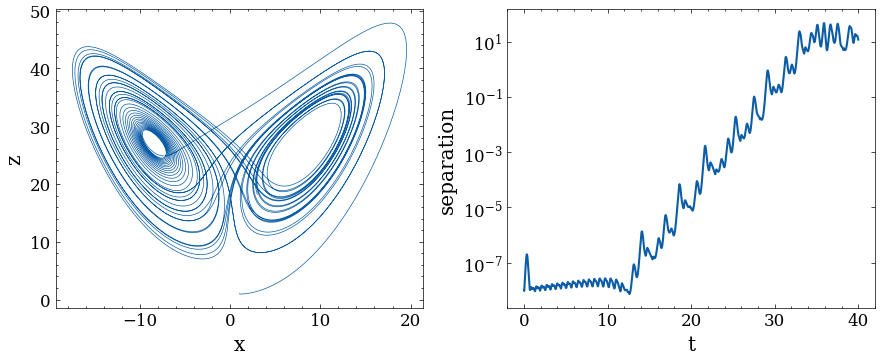

In [11]:
lor = lambda t, z: [10 * (z[1] - z[0]), z[0] * (28 - z[2]) - z[1], z[0] * z[1] - 8 / 3 * z[2]]
tl = np.linspace(0, 40, 8001)
s1 = solve_ivp(lor, [0, 40], [1, 1, 1], t_eval=tl, rtol=1e-11, atol=1e-12)
s2 = solve_ivp(lor, [0, 40], [1 + 1e-8, 1, 1], t_eval=tl, rtol=1e-11, atol=1e-12)
d = np.linalg.norm(s1.y - s2.y, axis=0)
print("separation at t = 10, 20, 30, 40:", [f"{d[np.searchsorted(tl, q)]:.1e}" for q in (10, 20, 30, 39.9)])
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
ax[0].plot(s1.y[0], s1.y[2], lw=0.5); ax[0].set(xlabel="x", ylabel="z")
ax[1].semilogy(tl, d); ax[1].set(xlabel="t", ylabel="separation"); plt.tight_layout(); plt.show()

## 9. Case study: 2021 MCM A, fungi (Team 2100454)

The team models $s$ fungal species with Gause's competition model, $F_i' = r_i F_i\bigl(1 - \sum_j c_{ij} F_j / n_j\bigr)$, plus the woody-fiber fraction $V$ and the hyphal lengths $l_i$:

$$V' = -\sum_i f\bigl(T, \phi, l_i'\bigr)\, V\, \Bigl(1 - \frac{\sum_j F_j}{K}\Bigr), \qquad l_i' = m_i\Bigl(1 - \frac{\sum_j F_j}{K}\Bigr).$$

Their Eq. (2) sets $c_{ij} = c_i = 1 - m_i/\sum_k m_k$ for $j \ne i$ and $c_{ii} = 1$. The three-species test (their Tables 3–4) uses extension rates $m = (1.5, 4.5, 10.5)$, growth rates $r = (0.1, 0.3, 0.7)$ per day, "consumption rates" $(1.2, 1.1, 1.0)$, $n_i = 100$, $K = 200$, $T = 22$ °C, $F(0) = (20, 15, 0.5)$ g/m², 122 days, Euler with $\Delta t = 1$ day. Below are values read off their Fig. 5 and Fig. 7.

In [12]:
days = np.array([0, 10, 15, 20, 40, 60, 80, 100, 120])
paper_F = np.array([[20.4, 28.3, 27.9, 26.5, 19.7, 14.1, 9.8, 6.7, 4.4],
                    [15.7, 49.3, 53.4, 52.3, 38.5, 24.8, 15.0, 8.8, 5.0],
                    [0.6, 11.9, 19.2, 24.8, 45.9, 64.5, 77.8, 86.5, 91.9]])          # read off their Fig. 5
paper_V = np.array([1.000, 0.970, 0.960, 0.950, 0.913, 0.878, 0.845, 0.811, 0.779])   # read off their Fig. 7
m3, r3, cons = np.array([1.5, 4.5, 10.5]), np.array([0.1, 0.3, 0.7]), np.array([1.2, 1.1, 1.0])
n3, K3 = 100.0, 200.0
c = 1 - m3 / m3.sum()
C_eq2 = np.tile(c[:, None], (1, 3)); np.fill_diagonal(C_eq2, 1.0)
C_cons = np.tile(cons[:, None], (1, 3))                  # consumption rate of species i weighs every species
def fungi(C, dt=1.0, T=125, lam=0.2225):
    F, V = np.array([20, 15, 0.5]), 1.0; Fs, Vs = [F.copy()], [V]
    for _ in range(int(round(T / dt))):
        crowd = 1 - F.sum() / K3
        f = np.exp(2.633) * (m3 * crowd) ** lam / 100 / 122    # their decomposition rate at 22 C, per day
        F = F + dt * r3 * F * (1 - C @ F / n3)
        V = V - dt * f.sum() * V * crowd
        Fs.append(F.copy()); Vs.append(V)
    return np.array(Fs), np.array(Vs)
print("c from Eq. (2):", c.round(3))
for name, C in [("Eq. (2) as printed", C_eq2), ("consumption rates as c_ij", C_cons)]:
    Fs, Vs = fungi(C)
    rms = np.sqrt(np.mean((Fs[days].T - paper_F) ** 2))
    print(f"{name:28s} F(120) = {Fs[120].round(1)}  rms gap to Fig. 5 = {rms:5.1f} g/m2   V(120) = {Vs[120]:.3f} (Fig. 7: 0.779)")
print("paper Fig. 5 at day 120:", paper_F[:, -1])

c from Eq. (2): [0.909 0.727 0.364]
Eq. (2) as printed           F(120) = [ 4.7 33.5 86.1]  rms gap to Fig. 5 =  18.3 g/m2   V(120) = 0.833 (Fig. 7: 0.779)
consumption rates as c_ij    F(120) = [ 4.7  5.4 89.5]  rms gap to Fig. 5 =   3.9 g/m2   V(120) = 0.766 (Fig. 7: 0.779)
paper Fig. 5 at day 120: [ 4.4  5.  91.9]


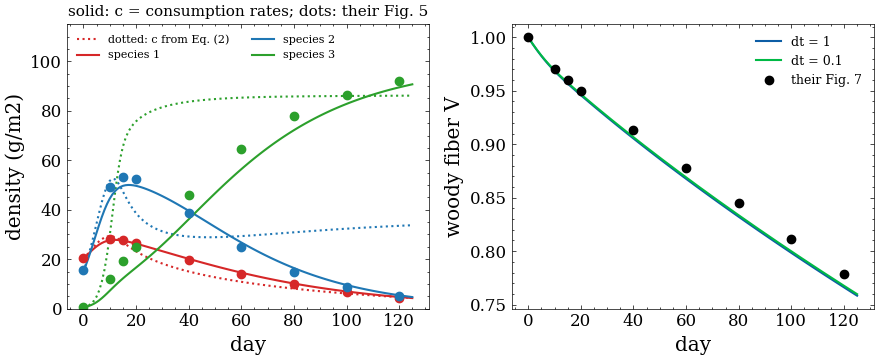

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
for C, ls, lab in [(C_eq2, ":", "Eq. (2)"), (C_cons, "-", "consumption")]:
    Fs, _ = fungi(C)
    for i, col in enumerate(["tab:red", "tab:blue", "tab:green"]):
        ax[0].plot(Fs[:, i], ls, c=col, label=(f"species {i+1}" if lab == "consumption" else ("dotted: c from Eq. (2)" if i == 0 else None)))
for i, col in enumerate(["tab:red", "tab:blue", "tab:green"]):
    ax[0].plot(days, paper_F[i], "o", c=col)
ax[0].set(xlabel="day", ylabel="density (g/m2)", title="solid: c = consumption rates; dots: their Fig. 5", ylim=(0, 115)); ax[0].legend(loc="upper left", ncol=2, fontsize=8)
for dt in [1, 0.1]:
    Fs, Vs = fungi(C_cons, dt); ax[1].plot(np.arange(len(Vs)) * dt, Vs, label=f"dt = {dt}")
ax[1].plot(days, paper_V, "ko", label="their Fig. 7"); ax[1].set(xlabel="day", ylabel="woody fiber V"); ax[1].legend()
plt.tight_layout(); plt.show()

### Equilibria and stability of the three-species model

Rest points have, for each subset of surviving species, $\sum_j c_{ij}F_j = n$; the Jacobian $J_{ij} = \delta_{ij} r_i (1 - \sum_k c_{ik} F_k/n) - r_i F_i c_{ij}/n$ decides stability.

In [14]:
from itertools import product
def rest_points(C, r):
    out = []
    for mask in product([0, 1], repeat=3):
        idx = [i for i in range(3) if mask[i]]; F = np.zeros(3)
        if idx:
            try: F[idx] = np.linalg.solve(C[np.ix_(idx, idx)] / n3, np.ones(len(idx)))
            except np.linalg.LinAlgError: continue
        if (F < -1e-9).any(): continue
        J = np.diag(r * (1 - C @ F / n3)) - (r * F)[:, None] * C / n3
        ev = np.linalg.eigvals(J)
        out.append((F.round(1), np.sort(ev.real).round(3), "stable" if (ev.real < 0).all() else "unstable"))
    return out
for name, C in [("Eq. (2) as printed", C_eq2), ("consumption rates as c_ij", C_cons)]:
    print(name)
    for F, ev, st in rest_points(C, r3):
        print(f"   {str(F):22s} eigenvalues {ev}  {st}")
Fs, _ = fungi(C_cons, T=2000); print("consumption reading after 2000 days:", Fs[-1].round(2))

Eq. (2) as printed
   [0. 0. 0.]             eigenvalues [0.1 0.3 0.7]  unstable
   [  0.   0. 100.]       eigenvalues [-0.7    0.009  0.082]  unstable
   [  0. 100.   0.]       eigenvalues [-0.3    0.009  0.445]  unstable
   [ 0.  37.1 86.5]       eigenvalues [-0.639 -0.078 -0.012]  stable
   [100.   0.   0.]       eigenvalues [-0.1    0.082  0.445]  unstable
   [13.6  0.  95.1]       eigenvalues [-0.67  -0.009  0.063]  unstable
   [26.8 80.5  0. ]       eigenvalues [-0.26  -0.008  0.427]  unstable
consumption rates as c_ij
   [0. 0. 0.]             eigenvalues [0.1 0.3 0.7]  unstable
   [  0.   0. 100.]       eigenvalues [-0.7  -0.03 -0.02]  stable
   [ 0.  90.9  0. ]       eigenvalues [-0.3   -0.009  0.064]  unstable
   [83.3  0.   0. ]       eigenvalues [-0.1    0.025  0.117]  unstable
consumption reading after 2000 days: [  0.   0. 100.]


### The rain-forest panel and the Euler step

In the five-species runs the growth rates follow the climate, and in the hot, wet rain forest they reach about 2.6 per day. With trait values read off their Figs. 8–9 for 27 °C and 85% humidity (an approximation of ours), Euler with $\Delta t = 1$ day jumps back and forth; $\Delta t = 0.5$ settles. The fastest Jacobian eigenvalue at the survivors' rest point is about $-2.3$, and $|1 + \lambda\Delta t| > 1$ for $\Delta t = 1$.

dt = 1.0: last two steps of p.flav.s 32.9, 59.2
dt = 0.5: last two steps of p.flav.s 53.3, 53.3


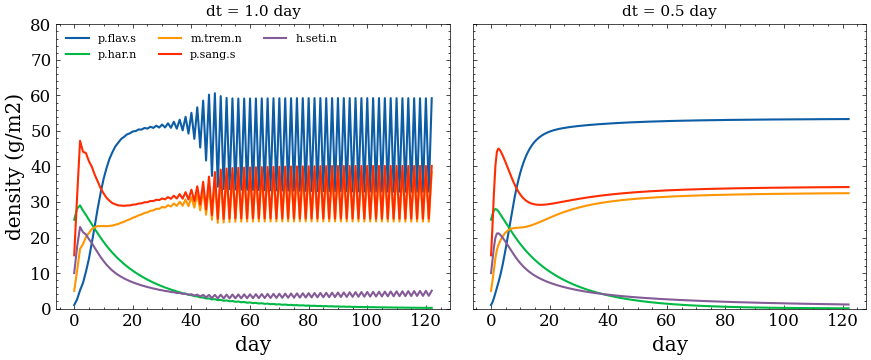

survivors' rest point [53.6  0.  32.9 34.6  0. ]  eigenvalues [-2.326 -0.3   -0.166 -0.048 -0.006]


In [15]:
m5 = np.array([13.2, 1.4, 10.1, 10.3, 7.2]); r5 = 0.2 * m5
c5 = 1 - m5 / m5.sum(); C5 = np.tile(c5[:, None], (1, 5)); np.fill_diagonal(C5, 1.0)
names = ["p.flav.s", "p.har.n", "m.trem.n", "p.sang.s", "h.seti.n"]
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for a_, dt in zip(ax, [1.0, 0.5]):
    F = np.array([1, 25, 5, 15, 10.]); tr = [F.copy()]
    for _ in range(int(122 / dt)):
        F = F + dt * r5 * F * (1 - C5 @ F / 100); tr.append(F.copy())
    tr = np.array(tr); tg = np.arange(len(tr)) * dt
    for i in range(5): a_.plot(tg, tr[:, i], label=names[i])
    a_.set(title=f"dt = {dt} day", xlabel="day", ylim=(0, 80)); print(f"dt = {dt}: last two steps of p.flav.s {tr[-2, 0]:.1f}, {tr[-1, 0]:.1f}")
ax[0].legend(loc="upper left", ncol=3, fontsize=8); ax[0].set_ylabel("density (g/m2)"); plt.tight_layout(); plt.show()
idx = [0, 2, 3]; Fe = np.zeros(5); Fe[idx] = np.linalg.solve(C5[np.ix_(idx, idx)] / 100, np.ones(3))
J = np.diag(r5 * (1 - C5 @ Fe / 100)) - (r5 * Fe)[:, None] * C5 / 100
print("survivors' rest point", Fe.round(1), " eigenvalues", np.sort(np.linalg.eigvals(J).real).round(3))

## Practice exercises

**These are practice for yourself, and they are not the graded assignments.** Problem sets are released separately on Blackboard, with due dates.

1. **Classify by hand.** For $x' = 2y$, $y' = -3x$ find the trajectories (they are ellipses) and confirm with `classify`.
2. **Concentration of force.** In `battle`, let 60,000 soldiers face 50,000 and 40,000 separately with $a = b$. Who wins, and with how many survivors?
3. **Harvesting the whales only.** Change the harvest so that only the whales are removed at rate $r y$. How do the averages move?
4. **Euler on the circle.** Run Euler and RK4 (`solve_ivp`) on $x' = -y$, $y' = x$ from $(1, 0)$ for 10 time units with $\Delta t = 0.1$. How much does $x^2 + y^2$ grow under Euler?
5. **Herd immunity.** For measles take $R_0 = 15$. What fraction must be vaccinated, and what happens to the peak of the outbreak in the SIR cell at 90% coverage?
6. **Fungi, two species.** Keep only species 2 and 3 of the case and the coefficients of Eq. (2). Find the rest points, check their stability, and confirm with a simulation that the two species coexist.
